<a href="https://colab.research.google.com/github/Darianath/ML/blob/main/%D0%9B%D0%B12_2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80%D0%BE%D0%B2%D0%B04_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import kagglehub
import os

path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "titanic.csv"))
df

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [95]:
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))

df.drop(['Ticket'], axis=1, inplace=True)
df.drop(['Parch'], axis=1, inplace=True)

In [96]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Fare,0
Cabin,687
Embarked,2


In [97]:
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]
df.head()


,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [98]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [99]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')


Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


/tmp/ipykernel_3731/3750547615.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})


In [100]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


In [101]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


In [102]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [103]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


In [104]:

male_survived = df[df['Sex'] == 0]['Survived'].mean() * 100
female_survived = df[df['Sex'] == 1]['Survived'].mean() * 100

print(f'Відсоток виживших чоловіків: {male_survived:.2f}%')
print(f'Відсоток виживших жінок: {female_survived:.2f}%')


Відсоток виживших чоловіків: 18.89%
Відсоток виживших жінок: 74.20%


In [107]:
class1_surv_rate = df[(df['Pclass'] == 1) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 1].shape[0]
class2_surv_rate = df[(df['Pclass'] == 2) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 2].shape[0]
class3_surv_rate = df[(df['Pclass'] == 3) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 3].shape[0]

print(f'Перший клас {class1_surv_rate * 100:.2f}%')
print(f'Другий клас {class2_surv_rate * 100:.2f}%')
print(f'Третій клас {class3_surv_rate * 100:.2f}%')

Перший клас 62.96%
Другий клас 47.28%
Третій клас 24.24%


In [108]:
survived_mean_age = df[df['Survived'] == 1]['Age'].mean()
not_survived_mean_age = df[df['Survived'] == 0]['Age'].mean()

print(f'Середній вік пасажирів, які вижили: {survived_mean_age:.2f}')
print(f'Середній вік пасажирів, які не вижили: {not_survived_mean_age:.2f}')

Середній вік пасажирів, які вижили: 28.29
Середній вік пасажирів, які не вижили: 30.03


In [111]:
df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)

for i in range(6):
    surv_rate = df[(df['Fare_Category'] == i) & (df['Survived'] == 1)].shape[0] / df[df['Fare_Category'] == i].shape[0]
    print(f'Частка пасажирів, які вижили, у групі {i}: {surv_rate * 100:.2f}%')

Частка пасажирів, які вижили, у групі 0: 20.51%
Частка пасажирів, які вижили, у групі 1: 19.08%
Частка пасажирів, які вижили, у групі 2: 36.69%
Частка пасажирів, які вижили, у групі 3: 43.62%
Частка пасажирів, які вижили, у групі 4: 41.78%
Частка пасажирів, які вижили, у групі 5: 69.80%


/tmp/ipykernel_3731/3363319728.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)


In [112]:
for i in range(1, 4):
    median_fare = df[df['Pclass'] == i]['Fare'].median()
    print(f'Середня вартість проїзду для даного класу  {i}: {median_fare:.2f}')

Середня вартість проїзду для даного класу  1: 60.29
Середня вартість проїзду для даного класу  2: 14.25
Середня вартість проїзду для даного класу  3: 8.05


<Axes: xlabel='Age', ylabel='Count'>

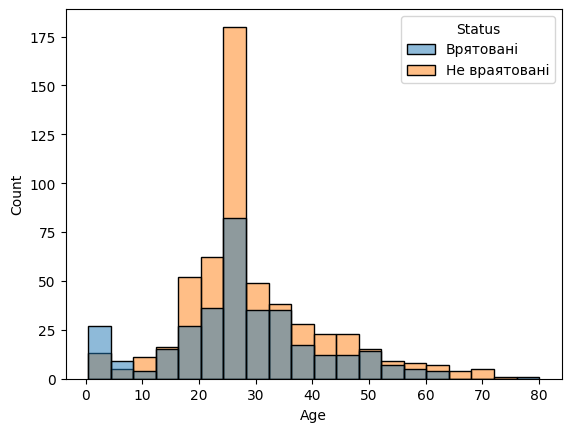

In [114]:
df_survived = df[df['Survived'] == 1][['Age']]
df_survived['Status'] = 'Врятовані'

df_not_survived = df[df['Survived'] == 0][['Age']]
df_not_survived['Status'] = 'Не враятовані'

df_combined = pd.concat([df_survived, df_not_survived])

sns.histplot(data=df_combined, x='Age', hue='Status', bins=20)

Вік відіграв ключову роль у катастрофі Титаніка, адже діти та пасажири похилого віку мали вищі шанси на порятунок.Натомість найбільшу групу жертв становили молоді дорослі пасажири віком від 20 до 30 років.

In [117]:
for i in range(1, 4):
    for j in range(2):
        surv_rate = df[(df['Pclass'] == i) & (df['Sex'] == j) & (df['Survived'] == 1)].shape[0] / df[(df['Pclass'] == i) & (df['Sex'] == j)].shape[0]
        print(f'Врятовано {"чоловіків" if j == 0 else "жінок"} класу {i}: {surv_rate * 100:.2f}%')

mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

Врятовано чоловіків класу 1: 36.89%
Врятовано жінок класу 1: 96.81%
Врятовано чоловіків класу 2: 15.74%
Врятовано жінок класу 2: 92.11%
Врятовано чоловіків класу 3: 13.54%
Врятовано жінок класу 3: 50.00%


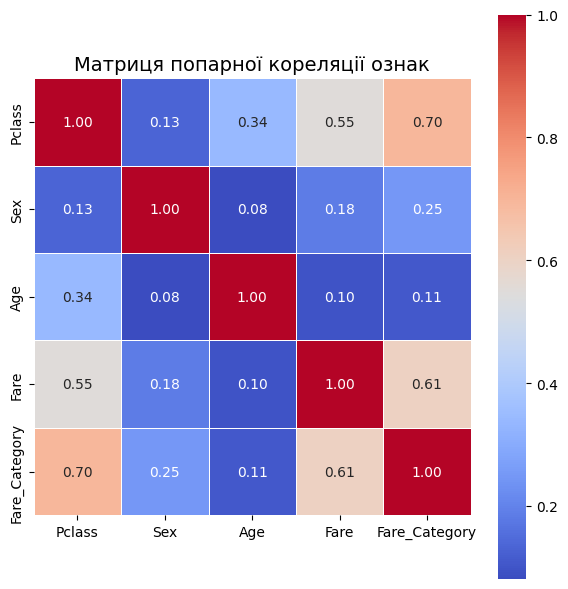

In [121]:
mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(6, 6))

sns.heatmap(
    mtx,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar=True,
    ax=ax
)

plt.title("Матриця попарної кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

In [135]:
import pandas as pd
import requests
from io import StringIO

url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22%27'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(6), object(3)
memory usage: 2.1+ KB


In [125]:
df.duplicated().sum()

np.int64(0)

In [126]:
df.isnull().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,0
2019,0


In [143]:

for col in df.columns[1:]:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace('—', 'nan', regex=False)
        .str.replace('-', 'nan', regex=False)
        .str.replace('*', '', regex=False),
        errors='coerce'
    )

In [144]:
df.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000,26.000000,24.000000
mean,23.092308,20.748148,15.585185,13.042857,8.207143,11.646429,11.142308,8.020833
std,2.822045,2.936032,1.870357,1.527872,1.556808,1.636274,2.011601,1.450331
min,18.600000,16.300000,12.700000,10.800000,6.100000,9.400000,5.100000,6.000000
25%,21.150000,18.650000,14.400000,12.225000,7.075000,10.450000,10.225000,6.800000
50%,22.600000,20.400000,15.200000,12.600000,7.850000,11.450000,11.150000,7.900000
75%,24.600000,22.050000,16.300000,14.050000,8.950000,12.250000,12.100000,8.800000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000,14.800000,11.000000


In [145]:
sorted_df = df[[region_col, last_year_col]].dropna().sort_values(by=last_year_col, ascending=False)

print(f"Аналізуємо показники за рік: {last_year_col}")
print("Топ-3 регіони з найвищим показником:")
display(sorted_df.head(3))

print("\nТоп-3 регіони з найнижчим показником:")
display(sorted_df.tail(3))

Аналізуємо показники за рік: 2019
Топ-3 регіони з найвищим показником:


,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4



Топ-3 регіони з найнижчим показником:


,Регіон,2019
22,Черкаська,6.4
24,Чернігівська,6.1
17,Сумська,6.0


In [146]:
region_col = df.columns[0]
latest_year_col = df.columns[-1]

print(f"Аналізуємо стовпець: '{latest_year_col}'")

df_sorted = df.sort_values(by=latest_year_col, ascending=False)

print("Регіони з найвищим коефіцієнтом народжуваності:")
display(df_sorted[[region_col, latest_year_col]].head(5))

print("Регіони з найнижчим коефіцієнтом народжуваності:")
display(df_sorted[[region_col, latest_year_col]].tail(5))

Аналізуємо стовпець: '2019'
Регіони з найвищим коефіцієнтом народжуваності:


,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2


Регіони з найнижчим коефіцієнтом народжуваності:


,Регіон,2019
17,Сумська,6.0
0,Крим,NaN
4,Донецька,NaN
11,Луганська,NaN
26,Севастополь,NaN


аналізуючиі данні за 19 рік ми бачимо що в деяких регіонах взагалі відсутняінформація про народжуваність тому можемо припустити що вона низька

/tmp/ipykernel_3731/2240865060.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


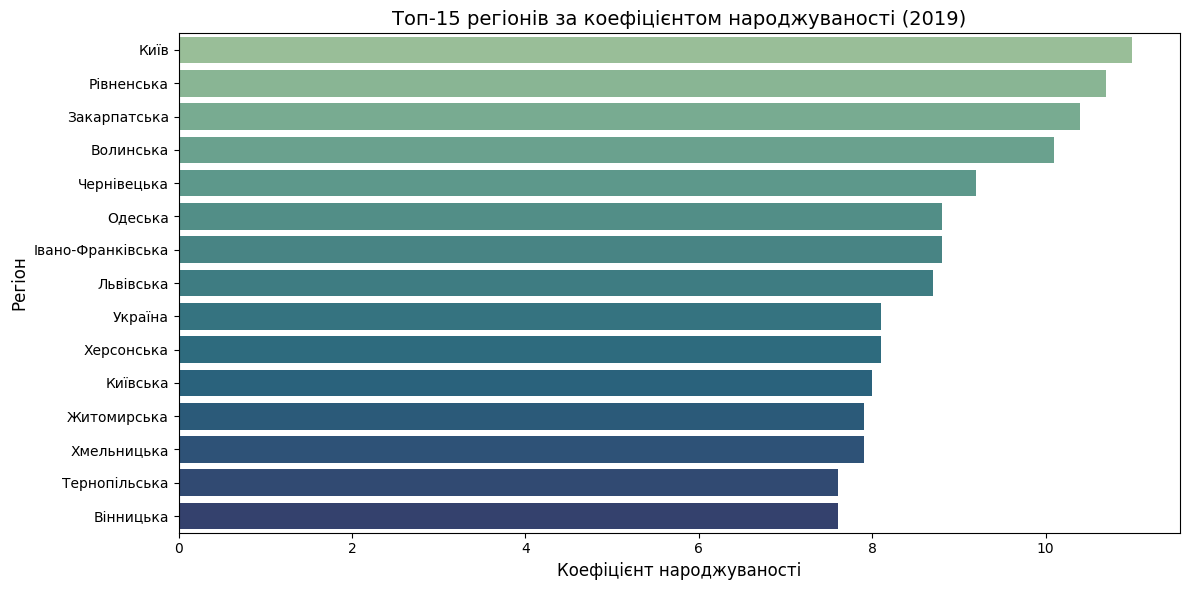

In [147]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_sorted.head(15),
    x=latest_year_col,
    y=region_col,
    palette='crest'
)

plt.title(f"Топ-15 регіонів за коефіцієнтом народжуваності ({latest_year_col})", fontsize=14)
plt.xlabel("Коефіцієнт народжуваності", fontsize=12)
plt.ylabel("Регіон", fontsize=12)
plt.tight_layout()
plt.show()

Бачимо що на 2019 рік Київ мав найвищій кофіціент народжуваності

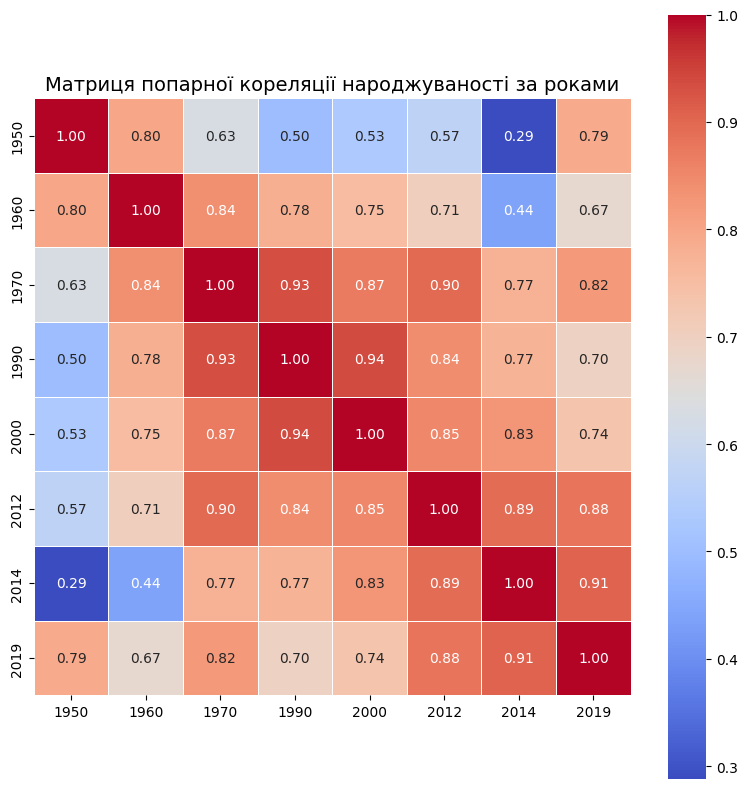

In [148]:

mtx = df.drop(columns=[region_col]).corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    mtx,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar=True,
    ax=ax
)

plt.title("Матриця попарної кореляції народжуваності за роками", fontsize=14)
plt.tight_layout()
plt.show()